# Assignment 3: Bank Customer Churn Classification

**Objective:** Given a bank customer, build a neural-network classifier to determine whether the customer will leave the bank in the next six months.

**Dataset:** The dataset contains 10,000 customer records with features such as CustomerId, CreditScore, Geography, Gender, Age, Tenure, and Balance. [Bank Customer Churn Modeling Dataset](https://www.kaggle.com/barelydedicated/bank-customer-churn-modeling)

**Tasks:**
1. Read the dataset.
2. Separate the feature and target sets and divide the data into training and test sets.
3. Normalize the train and test data.
4. Build and improve the neural-network model.
5. Print the accuracy score and confusion matrix.


In [46]:
%pip install keras jax


/usr/lib/python3.14/pty.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()


Note: you may need to restart the kernel to use updated packages.


In [2]:

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt #Importing the libraries

#for google colab
# import os
# import kagglehub
# path = kagglehub.dataset_download("barelydedicated/bank-customer-churn-modeling")

# print("Dataset downloaded successfully!")
# print("Dataset path:", path)


In [3]:
df = pd.read_csv("Churn_Modelling.csv")


# for google colab
# df = pd.read_csv(os.path.join(path, "Churn_Modelling.csv"))

# Preprocessing.

In [4]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [5]:
df.shape

(10000, 14)

In [6]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [7]:
df.isnull()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,False,False,False,False,False,False,False,False,False,False,False,False,False,False
9996,False,False,False,False,False,False,False,False,False,False,False,False,False,False
9997,False,False,False,False,False,False,False,False,False,False,False,False,False,False
9998,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [8]:
df.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


In [10]:
df.dtypes

RowNumber            int64
CustomerId           int64
Surname                str
CreditScore          int64
Geography              str
Gender                 str
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object

In [11]:
df.columns

Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='str')

In [12]:
df = df.drop(['RowNumber', 'Surname', 'CustomerId'], axis= 1) #Dropping the unnecessary columns

In [13]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


# Visualization

In [14]:
def visualization(x, y, xlabel):
    plt.figure(figsize=(10,5))
    plt.hist([x, y], color=['red', 'green'], label = ['exit', 'not_exit'])
    plt.xlabel(xlabel,fontsize=20)
    plt.ylabel("No. of customers", fontsize=20)
    plt.legend()

In [15]:
df_churn_exited = df[df['Exited']==1]['Tenure']
df_churn_not_exited = df[df['Exited']==0]['Tenure']

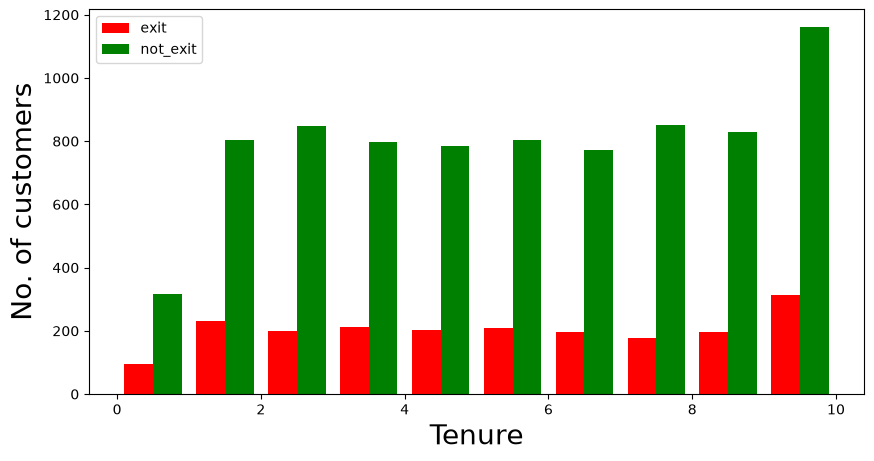

In [16]:
visualization(df_churn_exited, df_churn_not_exited, "Tenure")

In [17]:
df_churn_exited2 = df[df['Exited']==1]['Age']
df_churn_not_exited2 = df[df['Exited']==0]['Age']

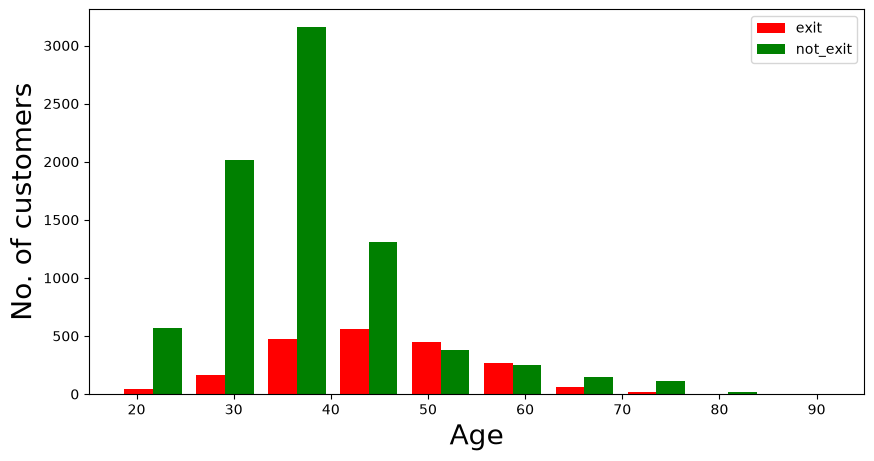

In [18]:
visualization(df_churn_exited2, df_churn_not_exited2, "Age")

# Converting the Categorical Variables

In [19]:
X = df[['CreditScore','Gender','Age','Tenure','Balance','NumOfProducts','HasCrCard','IsActiveMember','EstimatedSalary']]
states = pd.get_dummies(df['Geography'],drop_first = True)
gender = pd.get_dummies(df['Gender'],drop_first = True)

In [20]:

df = pd.concat([df,gender,states], axis = 1)

# Splitting the training and testing Dataset

In [21]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Male,Germany,Spain
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1,False,False,False
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,False,False,True
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,False,False,False
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0,False,False,False
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,False,False,True


In [22]:
X = df[['CreditScore','Age','Tenure','Balance','NumOfProducts','HasCrCard','IsActiveMember','EstimatedSalary','Male','Germany','Spain']]

In [23]:
y = df['Exited']

In [24]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.30)

# Normalizing the values with mean as 0 and Standard Deviation as 1

In [25]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()

In [26]:
X_train  = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [27]:
X_train

array([[-0.00982228, -0.37393021, -0.34345061, ..., -1.10522259,
        -0.57515083, -0.57603061],
       [ 1.32393931,  0.19951956,  0.70032113, ...,  0.90479511,
         1.73867435, -0.57603061],
       [ 1.51004558,  1.15526918,  0.35239722, ...,  0.90479511,
        -0.57515083, -0.57603061],
       ...,
       [ 0.26933713, -0.6606551 ,  0.00447331, ..., -1.10522259,
        -0.57515083, -0.57603061],
       [-0.28898168, -0.46950517,  0.70032113, ..., -1.10522259,
         1.73867435, -0.57603061],
       [-1.16781683,  2.5888936 ,  1.04824505, ...,  0.90479511,
         1.73867435, -0.57603061]], shape=(7000, 11))

In [28]:
X_test

array([[-1.26086997, -0.6606551 , -1.73514626, ..., -1.10522259,
        -0.57515083,  1.73601886],
       [-2.13970512, -0.94737998,  1.39616896, ..., -1.10522259,
         1.73867435, -0.57603061],
       [ 0.42442568, -0.85180502,  0.70032113, ...,  0.90479511,
         1.73867435, -0.57603061],
       ...,
       [ 0.46578263,  0.00836964,  0.00447331, ..., -1.10522259,
        -0.57515083,  1.73601886],
       [ 1.22054694,  0.48624444,  0.35239722, ..., -1.10522259,
        -0.57515083,  1.73601886],
       [ 0.25899789, -0.46950517,  1.74409287, ..., -1.10522259,
        -0.57515083, -0.57603061]], shape=(3000, 11))

# Building the Classifier Model using Keras

In [29]:
import os
os.environ["KERAS_BACKEND"] = "jax"
import keras #Keras is the wrapper on the top of TensorFlow/JAX
#Can use Tenserflow as well but won't be able to understand the errors initially.

In [30]:
from keras.models import Sequential #To create sequential neural network
from keras.layers import Dense #To create hidden layers

In [31]:
classifier = Sequential()

In [32]:
#To add the layers
#Dense helps to contruct the neurons
#Input Dimension means we have 11 features
# Units is to create the hidden layers
#Uniform helps to distribute the weight uniformly
classifier.add(Dense(activation = "relu",input_dim = 11,units = 6,kernel_initializer = "uniform"))

/home/vedant/Documents/LP-III/ML/.venv/lib/python3.14/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [33]:
classifier.add(Dense(activation = "relu",units = 6,kernel_initializer = "uniform"))   #Adding second hidden layers

In [34]:
classifier.add(Dense(activation = "sigmoid",units = 1,kernel_initializer = "uniform")) #Final neuron will be having siigmoid function

In [35]:
classifier.compile(optimizer="adam",loss = 'binary_crossentropy',metrics = ['accuracy']) #To compile the Artificial Neural Network. Ussed Binary crossentropy as we just have only two output

In [36]:
classifier.summary() #3 layers created. 6 neurons in 1st,6neurons in 2nd layer and 1 neuron in last

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 6)              │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │            42 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             7 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121 (484.00 B)

 Trainable params: 121 (484.00 B)

 Non-trainable params: 0 (0.00 B)

In [37]:
classifier.fit(X_train,y_train,batch_size=10,epochs=50) #Fitting the ANN to training dataset

Epoch 1/50


/home/vedant/Documents/LP-III/ML/.venv/lib/python3.14/site-packages/jax/_src/core.py:1980: UserWarning: Explicitly requested dtype int64 requested in ShapeDtypeStruct is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  return aval_fn(x)


700/700 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.7936 - loss: 0.5145
Epoch 2/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7941 - loss: 0.4241
Epoch 3/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7941 - loss: 0.4173
Epoch 4/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7986 - loss: 0.4092
Epoch 5/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8254 - loss: 0.4004
Epoch 6/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 1s 779us/step - accuracy: 0.8279 - loss: 0.3928
Epoch 7/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 1s 864us/step - accuracy: 0.8321 - loss: 0.3863
Epoch 8/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8431 - loss: 0.3806
Epoch 9/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 0s 654us/step - accuracy: 0.8467 - loss: 0.3765
Epoch 10/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 1s 762us/step - accuracy: 0.8484 - loss: 0.3732
Epoch 11/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8494 - loss: 0.3699
Epoch 12/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - 

In [38]:
y_pred =classifier.predict(X_test)
y_pred = (y_pred > 0.5) #Predicting the result

94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


In [39]:
from sklearn.metrics import confusion_matrix,accuracy_score,classification_report

In [40]:
cm = confusion_matrix(y_test,y_pred)

In [41]:
cm

array([[2265,  139],
       [ 296,  300]])

In [42]:
accuracy = accuracy_score(y_test,y_pred)

In [43]:
accuracy

0.855

Text(95.83333333333333, 0.5, 'Truth')

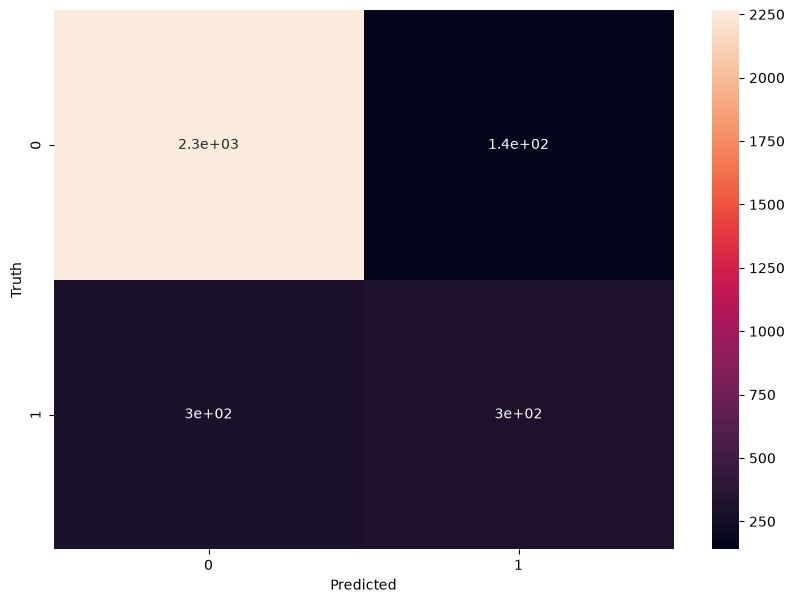

In [44]:
plt.figure(figsize = (10,7))
sns.heatmap(cm,annot = True)
plt.xlabel('Predicted')
plt.ylabel('Truth')

In [45]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.88      0.94      0.91      2404
           1       0.68      0.50      0.58       596

    accuracy                           0.85      3000
   macro avg       0.78      0.72      0.75      3000
weighted avg       0.84      0.85      0.85      3000

